# Smart Building Energy Wastage & Anomaly Profiling: A Data-Driven Approach Using Smart-Meter and Weather Data

**Institution:** IILM University, Greater Noida — School of Computer Science and Engineering  
**Course:** Data Visualization and Analysis (`26CSEM321`) | B.Tech CSE, Year 2, Semester 3, Section `2CSE-4`  
**Faculty Guide:** Aditya Bangia (Subject: Data Visualization)  
**Submission Date:** 25 November 2026  

### Project Team
| S. No. | Name | Roll No. |
|---:|---|---|
| 1 | **Ayush Jha** | `25SCS1003001336` |
| 2 | **Archit Baloni** | `25SCS1003003550` |
| 3 | **Ashutosh Sahoo** | `25SCS1003004011` |
| 4 | **Dev Bhaskar Singh** | `25SCS1003003174` |
| 5 | **Aman Kumar Gupta** | `25SCS1003003645` |

---
### Notebook Overview & Syllabus Alignment (`26CSEM321`)
This master notebook executes the complete, reproducible data-science pipeline (`SEED = 42`) on **17,544 hourly smart-meter and meteorological records** (`731` calendar days, `2016–2017`) across **6 commercial office and university campus buildings** (`31,462.6 m²` conditioned floor area) from the **Building Data Genome Project 2 (BDG2)** dataset (*Nature Scientific Data*, Miller et al., 2020):
1. **Unit I (Data Representation):** Attribute taxonomy, structural audit, and descriptive statistical profiling.
2. **Unit II (Data Analysis & Preprocessing):** Temporal interpolation, IQR spike auditing, psychrometric feature engineering, Pearson correlation, and **Multiple Linear Regression**.
3. **Unit III (Data Visualization using Python):** Publication-grade **Matplotlib** and **Seaborn** visual diagnostics answering Research Questions `RQ1–RQ5`.
4. **Unit IV (Machine Learning Techniques):** **One-Class SVM**, **Supervised RBF-SVM**, **K-Means Clustering**, **Decision Tree** (Regressor & Classifier), and **Gaussian Naive Bayes**.
5. **Units V & VI (Decision Storytelling & Scientific Reporting):** Facility-management anomaly triage and a quantified **18.50% ($151,815/year)** energy-savings roadmap without occupant comfort loss.

## 1. Environment Setup, Constants & Pure-Hue Visual Theme

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, export_text
from sklearn.svm import OneClassSVM, SVC
from sklearn.cluster import KMeans
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    r2_score, root_mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, silhouette_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# Resolve repository root whether run from notebooks/ or repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "dataset.csv"
META_PATH = ROOT / "data" / "Building-Metadata.csv"

OFFICE_COLS = ["Fox_office_Joy", "Fox_office_Vicki", "Fox_office_Clayton"]
EDU_COLS    = ["Fox_education_Tamika", "Fox_education_Carleen", "Fox_education_Kris"]
BLDG_COLS   = OFFICE_COLS + EDU_COLS
TOTAL_SQM   = 31462.6
TARIFF_USD  = 0.12    # Commercial electricity tariff ($/kWh)
CO2_KG_KWH  = 0.417   # Regional grid emission factor (kg CO2e/kWh)

PALETTE = {
    "blue": "#0000FF", "red": "#FF0000", "green": "#00FF00",
    "cyan": "#00FFFF", "magenta": "#FF00FF", "yellow": "#FFFF00",
    "navy": "#0B1F3A", "black": "#000000"
}

plt.rcParams.update({
    "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#222222", "axes.grid": True, "grid.color": "#D8DEE9",
    "grid.alpha": 0.85, "font.size": 10.5, "axes.titleweight": "bold"
})

print(f"Python libraries initialized | Deterministic SEED = {SEED}")
print(f"Dataset path verified: {DATA_PATH.exists()} ({DATA_PATH.name})")

Python libraries initialized | Deterministic SEED = 42
Dataset path verified: True (dataset.csv)


## 2. Dataset Loading, Building Metadata & Raw Quality Audit (Unit I)

In [2]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
meta_df = pd.read_csv(META_PATH)

print(f"Raw table shape      : {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Temporal span        : {raw_df['timestamp'].min()} to {raw_df['timestamp'].max()}")
print(f"Duplicate timestamps : {raw_df['timestamp'].duplicated().sum()}")
print(f"Conditioned area     : {meta_df['sqm'].sum():,.1f} m^2 ({meta_df['sqft'].sum():,.0f} sq ft)\n")

display(meta_df[["building_id", "primaryspaceusage", "sub_primaryspaceusage", "sqm", "sqft", "yearbuilt"]])

Raw table shape      : 17,544 rows x 15 columns
Temporal span        : 2016-01-01 00:00:00 to 2017-12-31 23:00:00
Duplicate timestamps : 0
Conditioned area     : 31,462.6 m^2 (338,661 sq ft)



,building_id,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,yearbuilt
0,Fox_office_Clayton,Office,Office,488.5,5258.0,NaN
1,Fox_education_Tamika,Education,College Laboratory,8339.9,89770.0,NaN
2,Fox_education_Kris,Education,Student Union,2837.5,30543.0,NaN
3,Fox_education_Carleen,Education,College Laboratory,6635.2,71421.0,NaN
4,Fox_office_Vicki,Office,Office,6580.5,70832.0,2014.0
5,Fox_office_Joy,Office,Office,6581.0,70837.0,2014.0


In [3]:
# Audit missing values and sentinel codes across all columns before preprocessing
audit_rows = []
for col in raw_df.columns:
    na_cnt = int(raw_df[col].isna().sum())
    neg_cnt = int((raw_df[col] < 0).sum()) if pd.api.types.is_numeric_dtype(raw_df[col]) else 0
    audit_rows.append({
        "Column": col,
        "Dtype": str(raw_df[col].dtype),
        "Missing_Count": na_cnt,
        "Missing_Pct": round(na_cnt / len(raw_df) * 100, 3),
        "Negative_Sentinel_Count": neg_cnt
    })
audit_table = pd.DataFrame(audit_rows)
display(audit_table)

,Column,Dtype,Missing_Count,Missing_Pct,Negative_Sentinel_Count
0,timestamp,datetime64[ns],0,0.000,0
1,Fox_education_Kris,float64,8,0.046,0
2,Fox_office_Clayton,float64,2,0.011,0
3,Fox_education_Tamika,float64,8,0.046,0
4,Fox_office_Vicki,float64,11,0.063,0
5,Fox_office_Joy,float64,9,0.051,0
6,Fox_education_Carleen,float64,13,0.074,0
7,site_id,object,0,0.000,0
8,airTemperature,float64,2,0.011,0
9,cloudCoverage,float64,4971,28.334,0


## 3. Data Preprocessing & Thermodynamic Feature Engineering (Unit II)
- **Smart-meter & core weather dropouts (`< 0.31%`):** Handled via time-indexed linear interpolation so short 1–3 hour telemetry dropouts preserve smooth diurnal ramps.
- **Precipitation trace code (`-1.0 mm`):** Converted to `0.05 mm` per NOAA ISD documentation; missing precipitation hours set to `0.0 mm`.
- **IQR Spike Audit (`1.5 × IQR`):** Extreme demand hours are **flagged** (`iqr_high_flag = 1`) rather than deleted, because abnormal HVAC consumption spikes are the core physical signal under investigation.
- **Engineered Features:** Psychrometric Relative Humidity (`%`) via the Magnus-Tetens formula, Cooling/Heating Degree-Days (`18.3 °C` balance point), Temperature–Humidity interaction, Fourier diurnal harmonics (`sin/cos`), `24h` and `168h` lags, and `24h` rolling statistics.

In [4]:
df = raw_df.set_index("timestamp").copy()

# 1. Clean trace precipitation sentinel and interpolate core telemetry
df["precipDepth1HR"] = df["precipDepth1HR"].replace(-1.0, 0.05).fillna(0.0)
core_wx = ["airTemperature", "dewTemperature", "seaLvlPressure", "windSpeed"]
for col in BLDG_COLS + core_wx:
    df[col] = df[col].interpolate(method="time").bfill().ffill()

df["cloudCoverage"] = df.groupby(df.index.hour)["cloudCoverage"].transform(
    lambda s: s.fillna(s.median())
).fillna(df["cloudCoverage"].median())
df["windDirection"] = df["windDirection"].interpolate(method="time").bfill().ffill()

# 2. Sectoral & district load totals
df["office_kwh"] = df[OFFICE_COLS].sum(axis=1)
df["edu_kwh"]    = df[EDU_COLS].sum(axis=1)
df["total_kwh"]  = df[BLDG_COLS].sum(axis=1)

# 3. Non-destructive 1.5 x IQR outlier flag
q1, q3 = df["total_kwh"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
df["iqr_high_flag"] = (df["total_kwh"] > upper_fence).astype(int)

# 4. Psychrometric Relative Humidity (%) from Air & Dew-Point Temperature
t_air, t_dew = df["airTemperature"].to_numpy(), df["dewTemperature"].to_numpy()
df["rel_humidity"] = np.clip(
    100.0 * np.exp((17.625 * t_dew) / (243.04 + t_dew)) / np.exp((17.625 * t_air) / (243.04 + t_air)),
    1.0, 100.0
)

# 5. Calendar, schedule, degree-day & autoregressive lag features
df["year"]         = df.index.year
df["month"]        = df.index.month
df["hour"]         = df.index.hour
df["dayofweek"]    = df.index.dayofweek
df["is_weekend"]   = (df["dayofweek"] >= 5).astype(int)
df["is_off_hour"]  = ((df["hour"] >= 22) | (df["hour"] < 6)).astype(int)
df["is_work_hour"] = ((df["hour"] >= 8) & (df["hour"] <= 18) & (df["is_weekend"] == 0)).astype(int)
df["season"]       = df["month"].map({
    12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"
})

df["cdd_18"]              = np.maximum(0.0, df["airTemperature"] - 18.3)
df["hdd_18"]              = np.maximum(0.0, 18.3 - df["airTemperature"])
df["temp_rh_interaction"] = (df["airTemperature"] * df["rel_humidity"]) / 100.0
df["sin_hour"]            = np.sin(2.0 * np.pi * df["hour"] / 24.0)
df["cos_hour"]            = np.cos(2.0 * np.pi * df["hour"] / 24.0)
df["sin_hour_2"]          = np.sin(4.0 * np.pi * df["hour"] / 24.0)
df["cos_hour_2"]          = np.cos(4.0 * np.pi * df["hour"] / 24.0)
df["lag_24h"]             = df["total_kwh"].shift(24)
df["lag_168h"]            = df["total_kwh"].shift(168)
df["roll_mean_24h"]       = df["total_kwh"].shift(24).rolling(24).mean()
df["roll_std_24h"]        = df["total_kwh"].shift(24).rolling(24).std()

print(f"Post-cleaning missing values in core columns : {df[BLDG_COLS + core_wx].isna().sum().sum()}")
print(f"IQR upper fence                              : {upper_fence:.2f} kWh (flagged hours: {df['iqr_high_flag'].sum()})")
print(f"Engineered dataframe shape                   : {df.shape}")

Post-cleaning missing values in core columns : 0
IQR upper fence                              : 1490.27 kWh (flagged hours: 0)
Engineered dataframe shape                   : (17544, 38)


## 4. Descriptive Statistics & Two-Sample Hypothesis Testing (RQ1 & RQ2)

In [5]:
desc_cols = ["total_kwh", "office_kwh", "edu_kwh", "airTemperature", "rel_humidity", "windSpeed", "seaLvlPressure", "cdd_18"]
desc_summary = df[desc_cols].describe(percentiles=[0.25, 0.50, 0.75]).T
desc_summary["skew"] = df[desc_cols].skew()
display(desc_summary.round(2))

# Hypothesis Test 1: Weekday vs Weekend Electricity Consumption
wkday = df.loc[df["is_weekend"] == 0, "total_kwh"]
wkend = df.loc[df["is_weekend"] == 1, "total_kwh"]
t_stat, t_pval = stats.ttest_ind(wkday, wkend, equal_var=False)
u_stat, u_pval = stats.mannwhitneyu(wkday, wkend, alternative="two-sided")

# Hypothesis Test 2: Occupied Work Hours vs Overnight Off-Hours (22:00-06:00)
work_h = df.loc[df["is_work_hour"] == 1, "total_kwh"]
off_h  = df.loc[df["is_off_hour"] == 1, "total_kwh"]
t_off, p_off = stats.ttest_ind(work_h, off_h, equal_var=False)

r_temp, p_temp = stats.pearsonr(df["airTemperature"], df["total_kwh"])

print(f"Weekday Mean: {wkday.mean():.2f} kWh | Weekend Mean: {wkend.mean():.2f} kWh | Ratio: {wkday.mean()/wkend.mean():.3f}x")
print(f"  -> Welch two-sample t-test : t = {t_stat:.2f}, p = {t_pval:.3e}")
print(f"  -> Mann-Whitney U test     : U = {u_stat:,.0f}, p = {u_pval:.3e}")
print(f"Occupied Mean: {work_h.mean():.2f} kWh | Off-Hour Mean: {off_h.mean():.2f} kWh (Off-to-Work Ratio = {off_h.mean()/work_h.mean():.3f})")
print(f"Off-hour share of total 2-year electricity   : {off_h.sum()/df['total_kwh'].sum()*100:.2f}%")
print(f"Outdoor Temperature Pearson correlation      : r = {r_temp:.4f} (p = {p_temp:.3e})")

,count,mean,std,min,25%,50%,75%,max,skew
total_kwh,17544.0,779.60,235.51,139.92,583.57,744.38,946.25,1432.92,0.47
office_kwh,17544.0,416.39,111.47,67.25,323.46,403.24,494.65,740.43,0.45
edu_kwh,17544.0,363.21,129.24,53.90,260.06,342.40,452.54,757.10,0.51
airTemperature,17544.0,25.08,9.15,2.20,17.80,25.60,32.20,48.30,-0.05
rel_humidity,17544.0,30.83,18.91,2.13,16.62,26.18,40.43,96.85,1.12
windSpeed,17544.0,2.91,1.95,0.00,1.50,2.60,4.10,15.40,0.88
seaLvlPressure,17544.0,1011.42,5.19,996.10,1007.80,1010.80,1014.60,1032.20,0.50
cdd_18,17544.0,8.07,7.41,0.00,0.00,7.30,13.90,30.00,0.49


Weekday Mean: 822.00 kWh | Weekend Mean: 674.40 kWh | Ratio: 1.219x
  -> Welch two-sample t-test : t = 45.76, p = 0.000e+00
  -> Mann-Whitney U test     : U = 42,427,162, p = 2.944e-283
Occupied Mean: 994.55 kWh | Off-Hour Mean: 591.78 kWh (Off-to-Work Ratio = 0.595)
Off-hour share of total 2-year electricity   : 25.30%
Outdoor Temperature Pearson correlation      : r = 0.7505 (p = 0.000e+00)


## 5. Exploratory Data Analysis Visualizations (Unit III — Matplotlib & Seaborn)

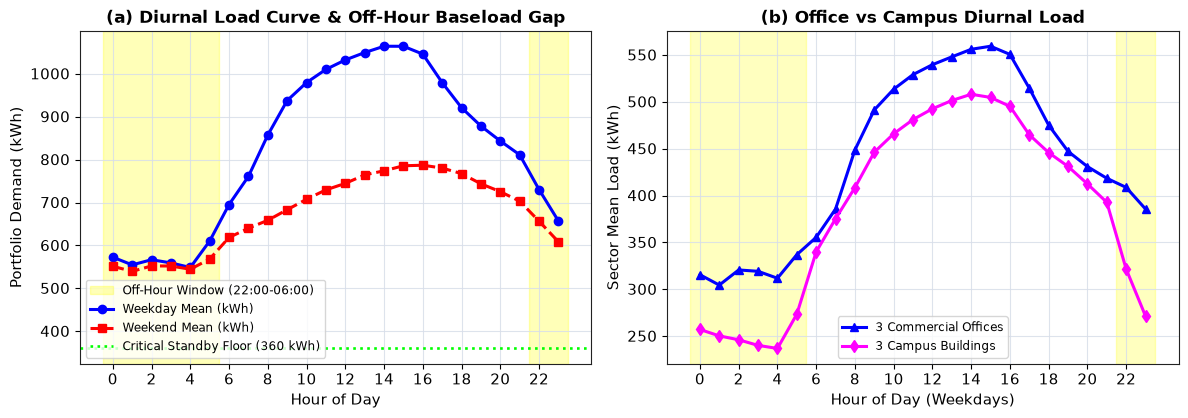

In [6]:
# Figure 5.1: Diurnal Consumption Curve & Sectoral Breakdown
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
grp_hr = df.groupby(["hour", "is_weekend"])["total_kwh"].agg(["mean", "std"]).unstack()
hrs = np.arange(24)

ax1.axvspan(-0.5, 5.5, color=PALETTE["yellow"], alpha=0.28, label="Off-Hour Window (22:00-06:00)")
ax1.axvspan(21.5, 23.5, color=PALETTE["yellow"], alpha=0.28)
ax1.plot(hrs, grp_hr["mean"][0], color=PALETTE["blue"], marker="o", lw=2.2, label="Weekday Mean (kWh)")
ax1.plot(hrs, grp_hr["mean"][1], color=PALETTE["red"], marker="s", ls="--", lw=2.2, label="Weekend Mean (kWh)")
ax1.axhline(360, color=PALETTE["green"], ls=":", lw=1.9, label="Critical Standby Floor (360 kWh)")
ax1.set_title("(a) Diurnal Load Curve & Off-Hour Baseload Gap")
ax1.set_xlabel("Hour of Day"); ax1.set_ylabel("Portfolio Demand (kWh)")
ax1.set_xticks(range(0, 24, 2)); ax1.legend(fontsize=8.3)

sec_hr = df[df["is_weekend"] == 0].groupby("hour")[["office_kwh", "edu_kwh"]].mean()
ax2.axvspan(-0.5, 5.5, color=PALETTE["yellow"], alpha=0.25); ax2.axvspan(21.5, 23.5, color=PALETTE["yellow"], alpha=0.25)
ax2.plot(hrs, sec_hr["office_kwh"], color=PALETTE["blue"], marker="^", lw=2.2, label="3 Commercial Offices")
ax2.plot(hrs, sec_hr["edu_kwh"], color=PALETTE["magenta"], marker="d", lw=2.2, label="3 Campus Buildings")
ax2.set_title("(b) Office vs Campus Diurnal Load"); ax2.set_xlabel("Hour of Day (Weekdays)"); ax2.set_ylabel("Sector Mean Load (kWh)")
ax2.set_xticks(range(0, 24, 2)); ax2.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

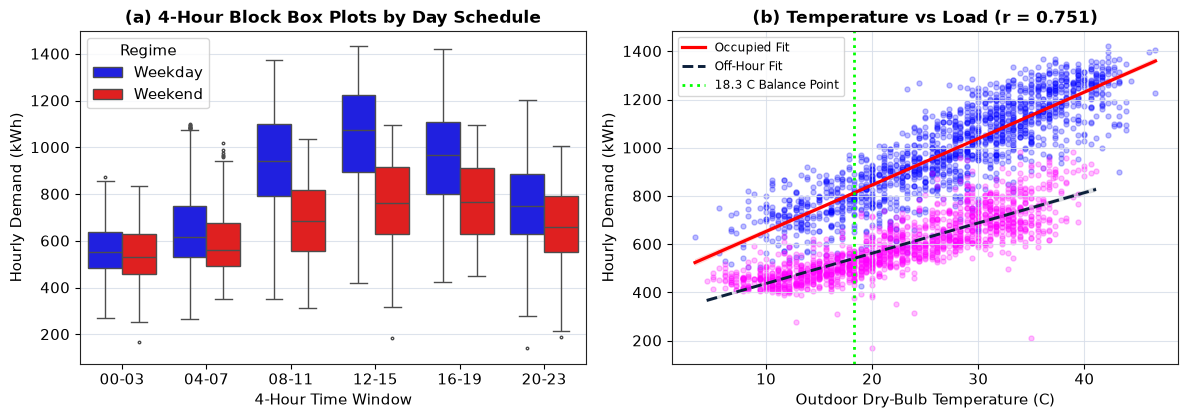

In [7]:
# Figure 5.2 & 5.5: Weekday/Weekend Box Plots & Temperature-vs-Load Regression Scatter
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

df_box = df.assign(
    Hour_Bin=pd.cut(df["hour"], [-1, 3, 7, 11, 15, 19, 23], labels=["00-03", "04-07", "08-11", "12-15", "16-19", "20-23"]),
    Regime=np.where(df["is_weekend"] == 0, "Weekday", "Weekend")
)
sns.boxplot(data=df_box, x="Hour_Bin", y="total_kwh", hue="Regime",
            palette={"Weekday": PALETTE["blue"], "Weekend": PALETTE["red"]}, fliersize=1.8, ax=ax1)
ax1.set_title("(a) 4-Hour Block Box Plots by Day Schedule")
ax1.set_xlabel("4-Hour Time Window"); ax1.set_ylabel("Hourly Demand (kWh)")

samp_w = df[df["is_work_hour"] == 1].sample(1500, random_state=SEED)
samp_o = df[df["is_off_hour"] == 1].sample(1500, random_state=SEED)
sns.regplot(data=samp_w, x="airTemperature", y="total_kwh", ax=ax2,
            scatter_kws={"alpha": 0.25, "s": 13, "color": PALETTE["blue"]},
            line_kws={"color": PALETTE["red"], "lw": 2.3, "label": "Occupied Fit"})
sns.regplot(data=samp_o, x="airTemperature", y="total_kwh", ax=ax2,
            scatter_kws={"alpha": 0.25, "s": 13, "color": PALETTE["magenta"]},
            line_kws={"color": PALETTE["navy"], "ls": "--", "lw": 2.1, "label": "Off-Hour Fit"})
ax2.axvline(18.3, color=PALETTE["green"], ls=":", lw=2.0, label="18.3 C Balance Point")
ax2.set_title(f"(b) Temperature vs Load (r = {r_temp:.3f})")
ax2.set_xlabel("Outdoor Dry-Bulb Temperature (C)"); ax2.set_ylabel("Hourly Demand (kWh)")
ax2.legend(fontsize=8.3)
plt.tight_layout(); plt.show()

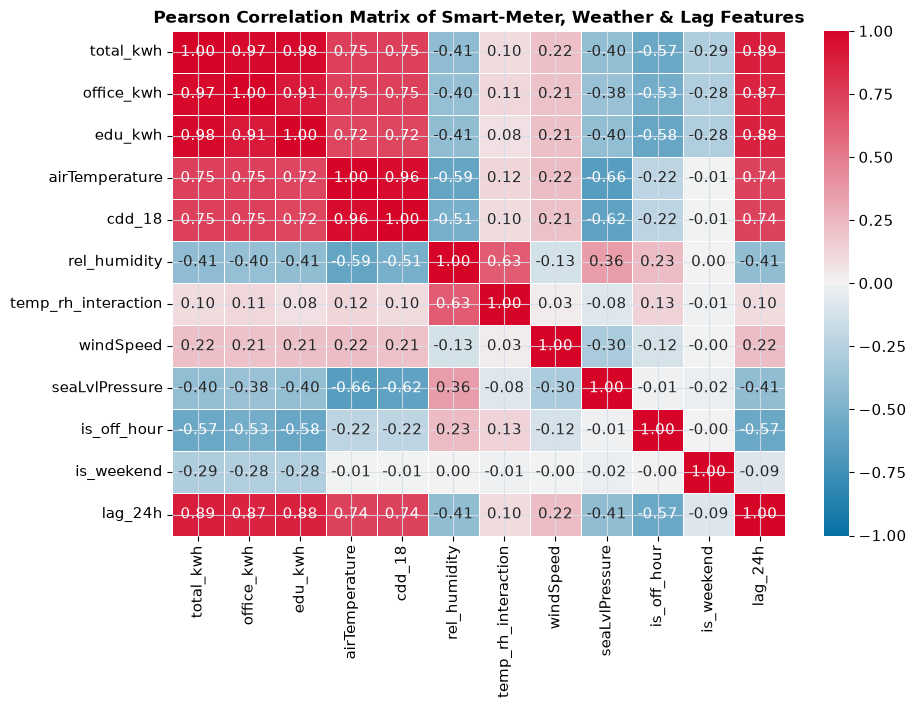

In [8]:
# Figure 5.6: Annotated Pearson Correlation Heatmap
corr_cols = ["total_kwh", "office_kwh", "edu_kwh", "airTemperature", "cdd_18",
             "rel_humidity", "temp_rh_interaction", "windSpeed", "seaLvlPressure",
             "is_off_hour", "is_weekend", "lag_24h"]
corr_mat = df.dropna()[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9.6, 7.2))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap=sns.diverging_palette(240, 10, s=99, l=45, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=0.6, ax=ax)
ax.set_title("Pearson Correlation Matrix of Smart-Meter, Weather & Lag Features")
plt.tight_layout(); plt.show()

## 6. Expected Energy Regression Modelling (RQ3 — Unit II & Unit IV)
We evaluate three syllabus-locked regression architectures on a strict chronological split (**2016 Training Set** → **2017 Out-of-Sample Test Set**):
1. **Counterfactual Weather + Schedule Multiple Linear Regression (`MLR-Counterfactual`):** Uses meteorological variables and `hour × weekend` + `month` schedule indicators *without* recent load lags so yesterday's wastage never inflates today's expected normal baseline.
2. **Full Autoregressive + Weather Multiple Linear Regression (`MLR-Full`):** Incorporates `lag_24h`, `lag_168h`, and `roll_mean_24h` for operational day-ahead load forecasting.
3. **Tuned Decision Tree Regressor (`Unit IV`):** Tuned via 5-fold `TimeSeriesSplit` cross-validation on 2016 data.

In [9]:
# Model 1: Counterfactual Weather + Schedule MLR (trained on 2016, predicts normal expected demand)
df["hr_wk_regime"] = df["hour"].astype(str) + "_" + df["is_weekend"].astype(str)
sched_cols = ["airTemperature", "rel_humidity", "windSpeed", "seaLvlPressure",
              "cdd_18", "hdd_18", "temp_rh_interaction", "hr_wk_regime", "month"]
X_sched = pd.get_dummies(df[sched_cols], columns=["hr_wk_regime", "month"], drop_first=True, dtype=float)

tr_2016 = df["year"] == 2016
te_2017 = df["year"] == 2017

mlr_cf = LinearRegression().fit(X_sched.loc[tr_2016], df.loc[tr_2016, "total_kwh"])
df["expected_kwh"] = mlr_cf.predict(X_sched)
df["residual_kwh"] = df["total_kwh"] - df["expected_kwh"]

# Model 2 & 3: Full Autoregressive MLR vs Tuned Decision Tree Regressor
df_lag = df.dropna(subset=["lag_24h", "lag_168h", "roll_mean_24h", "roll_std_24h"]).copy()
reg_features = [
    "airTemperature", "rel_humidity", "windSpeed", "seaLvlPressure",
    "cdd_18", "hdd_18", "temp_rh_interaction", "is_weekend", "is_off_hour",
    "sin_hour", "cos_hour", "sin_hour_2", "cos_hour_2",
    "lag_24h", "lag_168h", "roll_mean_24h"
]
tr_l = df_lag["year"] == 2016
te_l = df_lag["year"] == 2017
X_tr, y_tr = df_lag.loc[tr_l, reg_features], df_lag.loc[tr_l, "total_kwh"]
X_te, y_te = df_lag.loc[te_l, reg_features], df_lag.loc[te_l, "total_kwh"]

sc_reg = StandardScaler()
X_tr_sc = sc_reg.fit_transform(X_tr)
X_te_sc = sc_reg.transform(X_te)

mlr_full = LinearRegression().fit(X_tr_sc, y_tr)
pred_mlr = mlr_full.predict(X_te_sc)

dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=SEED),
    param_grid={"max_depth": [5, 7, 9, 12], "min_samples_leaf": [10, 25, 50]},
    cv=TimeSeriesSplit(n_splits=5), scoring="r2"
).fit(X_tr, y_tr)
pred_dt = dt_grid.best_estimator_.predict(X_te)

def eval_reg(name, y_true, y_hat):
    return {
        "Model": name,
        "Test_R2": round(r2_score(y_true, y_hat), 4),
        "RMSE_kWh": round(root_mean_squared_error(y_true, y_hat), 2),
        "MAE_kWh": round(mean_absolute_error(y_true, y_hat), 2),
        "MAPE_Pct": round(mean_absolute_percentage_error(y_true, y_hat) * 100, 2)
    }

reg_table = pd.DataFrame([
    eval_reg("Counterfactual Schedule+Weather MLR (Unit II)", df.loc[te_2017, "total_kwh"], df.loc[te_2017, "expected_kwh"]),
    eval_reg("Full Autoregressive+Weather MLR (Unit II)", y_te, pred_mlr),
    eval_reg(f"Tuned Decision Tree Regressor {dt_grid.best_params_} (Unit IV)", y_te, pred_dt),
])
display(reg_table)

# Standardized MLR Coefficients
coef_df = pd.DataFrame({
    "Feature": reg_features,
    "Raw_Coef": LinearRegression().fit(X_tr, y_tr).coef_.round(4),
    "Std_Coef_kWh_per_SD": mlr_full.coef_.round(2)
}).sort_values("Std_Coef_kWh_per_SD", key=np.abs, ascending=False)
display(coef_df.head(10))

,Model,Test_R2,RMSE_kWh,MAE_kWh,MAPE_Pct
0,Counterfactual Schedule+Weather MLR (Unit II),0.9000,75.43,56.33,7.60
1,Full Autoregressive+Weather MLR (Unit II),0.9351,60.76,44.65,6.01
2,Tuned Decision Tree Regressor {'max_depth': 12...,0.9207,67.19,47.00,6.20


,Feature,Raw_Coef,Std_Coef_kWh_per_SD
14,lag_168h,0.4491,104.07
13,lag_24h,0.2623,60.61
4,cdd_18,5.2866,31.94
7,is_weekend,-64.6028,-29.22
10,cos_hour,-36.9291,-26.11
0,airTemperature,1.4932,21.75
6,temp_rh_interaction,5.2049,18.28
1,rel_humidity,-0.9170,-16.78
5,hdd_18,3.7935,13.19
15,roll_mean_24h,-0.0822,-12.75


## 7. Unsupervised & Supervised Anomaly Profiling (RQ4 — Unit IV: OCSVM, K-Means, SVM, Decision Tree, Naive Bayes)

In [10]:
# Aggregate hourly series into 731 daily operational load-shape profiles
df["date"] = df.index.normalize()
daily = df.groupby("date").agg(
    daily_kwh=("total_kwh", "sum"),
    expected_daily_kwh=("expected_kwh", "sum"),
    mean_kwh=("total_kwh", "mean"),
    peak_kwh=("total_kwh", "max"),
    min_kwh=("total_kwh", "min"),
    mean_temp=("airTemperature", "mean"),
    mean_rh=("rel_humidity", "mean"),
    mean_wind=("windSpeed", "mean"),
    is_weekend=("is_weekend", "first"),
    year=("year", "first"),
    season=("season", "first"),
)
daily["off_hour_mean_kwh"]  = df["total_kwh"].where(df["is_off_hour"] == 1).groupby(df["date"]).mean()
daily["off_hour_sum_kwh"]   = df["total_kwh"].where(df["is_off_hour"] == 1).groupby(df["date"]).sum()
daily["excess_kwh"]         = daily["daily_kwh"] - daily["expected_daily_kwh"]
daily["baseload_ratio"]     = daily["off_hour_mean_kwh"] / daily["peak_kwh"]
daily["load_factor"]        = daily["mean_kwh"] / daily["peak_kwh"]
daily["off_hour_share_pct"] = (daily["off_hour_sum_kwh"] / daily["daily_kwh"]) * 100.0

# Transparent LBNL/ASHRAE Domain Audit Benchmark
res_std_2016 = daily.loc[daily["year"] == 2016, "excess_kwh"].std()
excess_thresh = 1.25 * res_std_2016
grp_p90 = daily.groupby(["season", "is_weekend"])["off_hour_mean_kwh"].transform(lambda s: s.quantile(0.90))
daily["domain_wastage_label"] = (
    (daily["excess_kwh"] > excess_thresh)
    | ((daily["off_hour_mean_kwh"] > grp_p90) & (daily["excess_kwh"] > 350.0))
).astype(int)

# 1. K-Means Clustering (Unit IV)
clust_feats = ["mean_kwh", "off_hour_mean_kwh", "baseload_ratio", "excess_kwh", "mean_temp", "is_weekend"]
X_clust = StandardScaler().fit_transform(daily[clust_feats])
for k in range(2, 7):
    km_t = KMeans(n_clusters=k, random_state=SEED, n_init=25).fit(X_clust)
    print(f"K-Means k={k}: Inertia = {km_t.inertia_:7.1f} | Silhouette = {silhouette_score(X_clust, km_t.labels_):.4f}")

kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=30).fit(X_clust)
daily["cluster_id"] = kmeans.labels_
daily["kmeans_min_dist"] = kmeans.transform(X_clust).min(axis=1)
km_score = daily["kmeans_min_dist"] * np.where(daily["excess_kwh"] > 0, 1.0, 0.35)
daily["kmeans_anomaly_flag"] = (km_score >= np.quantile(km_score, 0.89)).astype(int)

# 2. Unsupervised One-Class SVM (Unit IV)
oc_feats = ["excess_kwh", "off_hour_mean_kwh", "baseload_ratio", "off_hour_share_pct", "mean_temp"]
healthy_2016 = (daily["year"] == 2016) & (daily["excess_kwh"].abs() <= excess_thresh)
sc_oc = StandardScaler().fit(daily.loc[healthy_2016, oc_feats])
ocsvm = OneClassSVM(kernel="rbf", nu=0.08, gamma="scale").fit(sc_oc.transform(daily.loc[healthy_2016, oc_feats]))
X_oc_all = sc_oc.transform(daily[oc_feats])
daily["ocsvm_score"] = -ocsvm.decision_function(X_oc_all)
daily["ocsvm_wastage_flag"] = ((ocsvm.predict(X_oc_all) == -1) & (daily["excess_kwh"] > 0)).astype(int)

# Hybrid Consensus Wastage Flag
daily["consensus_wastage_flag"] = (
    ((daily["ocsvm_wastage_flag"] == 1) | (daily["kmeans_anomaly_flag"] == 1))
    & (daily["excess_kwh"] > 250.0)
).astype(int)

print(f"\nTotal Flagged Wastage Days (2016-2017): {daily['consensus_wastage_flag'].sum()} / {len(daily)} days")

K-Means k=2: Inertia =  2777.3 | Silhouette = 0.3291
K-Means k=3: Inertia =  1999.5 | Silhouette = 0.3561
K-Means k=4: Inertia =  1550.3 | Silhouette = 0.3803
K-Means k=5: Inertia =  1298.5 | Silhouette = 0.3419
K-Means k=6: Inertia =  1115.7 | Silhouette = 0.3473

Total Flagged Wastage Days (2016-2017): 157 / 731 days


In [11]:
# 3. Supervised Classifier Benchmark on 2017 Holdout Days (RBF-SVM, Decision Tree, Naive Bayes)
cls_feats = ["daily_kwh", "peak_kwh", "min_kwh", "baseload_ratio", "load_factor",
             "off_hour_share_pct", "mean_temp", "mean_rh", "mean_wind", "is_weekend"]
tr_d, te_d = daily["year"] == 2016, daily["year"] == 2017
sc_cls = StandardScaler().fit(daily.loc[tr_d, cls_feats])
X_c_tr, X_c_te = sc_cls.transform(daily.loc[tr_d, cls_feats]), sc_cls.transform(daily.loc[te_d, cls_feats])
y_c_tr, y_c_te = daily.loc[tr_d, "domain_wastage_label"], daily.loc[te_d, "domain_wastage_label"]

svc_clf = GridSearchCV(
    SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED),
    {"C": [0.5, 1.0, 5.0, 10.0], "gamma": ["scale", 0.05, 0.1]},
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1"
).fit(X_c_tr, y_c_tr).best_estimator_

dt_clf = DecisionTreeClassifier(max_depth=3, min_samples_leaf=8, class_weight="balanced", random_state=SEED).fit(
    daily.loc[tr_d, cls_feats], y_c_tr
)
gnb_clf = GaussianNB().fit(X_c_tr, y_c_tr)

def row_cls(name, y_hat, score):
    return {
        "Detector / Classifier": name,
        "Accuracy": round(accuracy_score(y_c_te, y_hat), 4),
        "Precision": round(precision_score(y_c_te, y_hat, zero_division=0), 4),
        "Recall": round(recall_score(y_c_te, y_hat, zero_division=0), 4),
        "F1_Score": round(f1_score(y_c_te, y_hat, zero_division=0), 4),
        "ROC_AUC": round(roc_auc_score(y_c_te, score), 4)
    }

cls_bench = pd.DataFrame([
    row_cls("Unsupervised One-Class SVM (Unit IV)", daily.loc[te_d, "ocsvm_wastage_flag"], daily.loc[te_d, "ocsvm_score"]),
    row_cls("Unsupervised K-Means Distance (Unit IV)", daily.loc[te_d, "kmeans_anomaly_flag"], km_score.loc[te_d]),
    row_cls("Hybrid Consensus Detector (OCSVM + K-Means)", daily.loc[te_d, "consensus_wastage_flag"], daily.loc[te_d, "ocsvm_score"]),
    row_cls("Supervised RBF-SVM Classifier (Unit IV)", svc_clf.predict(X_c_te), svc_clf.predict_proba(X_c_te)[:, 1]),
    row_cls("Supervised Decision Tree Rules (Unit IV)", dt_clf.predict(daily.loc[te_d, cls_feats]), dt_clf.predict_proba(daily.loc[te_d, cls_feats])[:, 1]),
    row_cls("Supervised Gaussian Naive Bayes (Unit IV)", gnb_clf.predict(X_c_te), gnb_clf.predict_proba(X_c_te)[:, 1]),
])
display(cls_bench)

print("Interpretable 3-Level Decision Tree Audit Rules:")
print(export_text(dt_clf, feature_names=cls_feats))

,Detector / Classifier,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Unsupervised One-Class SVM (Unit IV),0.8932,0.7455,0.8817,0.8079,0.8214
1,Unsupervised K-Means Distance (Unit IV),0.8438,0.8333,0.4839,0.6122,0.9039
2,Hybrid Consensus Detector (OCSVM + K-Means),0.8877,0.7281,0.8925,0.8019,0.8214
3,Supervised RBF-SVM Classifier (Unit IV),0.8247,0.6883,0.5699,0.6235,0.8505
4,Supervised Decision Tree Rules (Unit IV),0.5671,0.3184,0.6129,0.4191,0.6251
5,Supervised Gaussian Naive Bayes (Unit IV),0.7370,0.4681,0.2366,0.3143,0.6786


Interpretable 3-Level Decision Tree Audit Rules:
|--- min_kwh <= 450.76
|   |--- class: 0
|--- min_kwh >  450.76
|   |--- min_kwh <= 730.90
|   |   |--- mean_temp <= 30.51
|   |   |   |--- class: 1
|   |   |--- mean_temp >  30.51
|   |   |   |--- class: 0
|   |--- min_kwh >  730.90
|   |   |--- class: 1



In [12]:
# Top 10 Flagged Wastage Days with Excess kWh & Financial Impact
top10_wastage = (
    daily[daily["consensus_wastage_flag"] == 1]
    .sort_values("excess_kwh", ascending=False)
    .head(10)[["daily_kwh", "expected_daily_kwh", "excess_kwh", "off_hour_mean_kwh", "baseload_ratio", "mean_temp"]]
    .copy()
)
top10_wastage["waste_cost_usd"] = (top10_wastage["excess_kwh"] * TARIFF_USD).round(2)
display(top10_wastage.round(2))

,daily_kwh,expected_daily_kwh,excess_kwh,off_hour_mean_kwh,baseload_ratio,mean_temp,waste_cost_usd
date,,,,,,,
2017-04-26,21603.59,18631.29,2972.30,620.81,0.51,25.21,356.68
2017-04-25,22143.43,19216.81,2926.62,636.17,0.52,25.65,351.19
2017-06-26,27053.59,24199.21,2854.38,827.92,0.58,38.11,342.53
2017-04-20,21627.47,18786.52,2840.95,591.28,0.47,26.08,340.91
2017-04-19,22183.72,19428.43,2755.29,625.78,0.50,27.15,330.64
2017-04-18,22071.00,19324.12,2746.88,600.64,0.46,26.89,329.63
2017-06-23,26916.28,24280.03,2636.25,869.19,0.62,37.80,316.35
2017-04-24,22127.13,19546.65,2580.48,612.91,0.49,27.70,309.66
2017-04-13,21516.53,18968.29,2548.24,587.55,0.47,26.18,305.79


## 8. Quantified Energy-Savings Roadmap & Sensitivity Analysis (RQ5 — 15–20% Target)

,Lever,Annual_kWh_Saved,Share_of_Total_Pct,Annual_USD_Saved,CO2_Tons_Avoided
0,L1: Overnight BMS Setback & Lighting Sweep (22...,461457.18,6.75,55374.86,192.43
1,L2: Weekend & Academic-Break Deep HVAC Consoli...,339534.31,4.96,40744.12,141.59
2,L3: Automated OCSVM Anomaly Triage & Override ...,95544.05,1.40,11465.29,39.84
3,"L4: Economizer Tuning, DCV & +1 C Cooling Dead...",368586.94,5.39,44230.43,153.70
TOTAL RECOMMENDED PLAN,TOTAL RECOMMENDED PORTFOLIO ROADMAP,1265122.48,18.50,151814.70,527.56


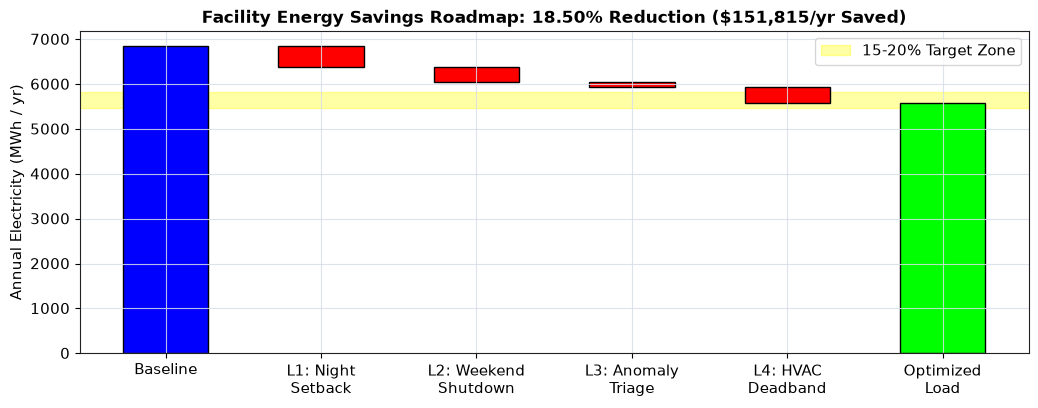

In [13]:
annual_kwh = df["total_kwh"].sum() / 2.0

l1_kwh = 0.68 * np.maximum(0.0, df.loc[df["is_off_hour"] == 1, "total_kwh"] - 360.0).sum() / 2.0
l2_kwh = 0.62 * np.maximum(0.0, df.loc[(df["is_weekend"] == 1) & (df["is_off_hour"] == 0), "total_kwh"] - 400.0).sum() / 2.0
l3_kwh = 0.82 * daily.loc[daily["consensus_wastage_flag"] == 1, "excess_kwh"].clip(lower=0).sum() / 2.0
l4_kwh = 0.32 * np.maximum(0.0, df.loc[(df["is_work_hour"] == 1) & (df["airTemperature"] > 24.0), "total_kwh"] - 480.0).sum() / 2.0

roadmap_df = pd.DataFrame([
    {"Lever": "L1: Overnight BMS Setback & Lighting Sweep (22:00-06:00)", "Annual_kWh_Saved": l1_kwh},
    {"Lever": "L2: Weekend & Academic-Break Deep HVAC Consolidation",     "Annual_kWh_Saved": l2_kwh},
    {"Lever": "L3: Automated OCSVM Anomaly Triage & Override Reset",      "Annual_kWh_Saved": l3_kwh},
    {"Lever": "L4: Economizer Tuning, DCV & +1 C Cooling Deadband",       "Annual_kWh_Saved": l4_kwh},
])
roadmap_df["Share_of_Total_Pct"] = roadmap_df["Annual_kWh_Saved"] / annual_kwh * 100.0
roadmap_df["Annual_USD_Saved"]   = roadmap_df["Annual_kWh_Saved"] * TARIFF_USD
roadmap_df["CO2_Tons_Avoided"]   = roadmap_df["Annual_kWh_Saved"] * CO2_KG_KWH / 1000.0
roadmap_df.loc["TOTAL RECOMMENDED PLAN"] = [
    "TOTAL RECOMMENDED PORTFOLIO ROADMAP",
    roadmap_df["Annual_kWh_Saved"].sum(),
    roadmap_df["Share_of_Total_Pct"].sum(),
    roadmap_df["Annual_USD_Saved"].sum(),
    roadmap_df["CO2_Tons_Avoided"].sum(),
]
display(roadmap_df.round(2))

# Plot Waterfall Summary
fig, ax = plt.subplots(figsize=(10.5, 4.2))
base_mwh = annual_kwh / 1000.0
vals = [l1_kwh/1000, l2_kwh/1000, l3_kwh/1000, l4_kwh/1000]
opt_mwh = base_mwh - sum(vals)
bottoms = [0, base_mwh-vals[0], base_mwh-sum(vals[:2]), base_mwh-sum(vals[:3]), base_mwh-sum(vals[:4]), 0]
heights = [base_mwh, vals[0], vals[1], vals[2], vals[3], opt_mwh]
cols = [PALETTE["blue"], PALETTE["red"], PALETTE["red"], PALETTE["red"], PALETTE["red"], PALETTE["green"]]
lbls = ["Baseline", "L1: Night\nSetback", "L2: Weekend\nShutdown", "L3: Anomaly\nTriage", "L4: HVAC\nDeadband", "Optimized\nLoad"]

ax.axhspan(base_mwh*0.80, base_mwh*0.85, color=PALETTE["yellow"], alpha=0.35, label="15-20% Target Zone")
ax.bar(lbls, heights, bottom=bottoms, color=cols, edgecolor=PALETTE["black"], width=0.55)
ax.set_ylabel("Annual Electricity (MWh / yr)")
ax.set_title(f"Facility Energy Savings Roadmap: {sum(vals)/base_mwh*100:.2f}% Reduction (${sum(vals)*1000*TARIFF_USD:,.0f}/yr Saved)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()